# K-Means Clustering of AIMO Observations

**Assignment A7** — Cluster the AIMO biomechanical observations (excluding scores), perform PCA, and visualise the first two principal component scores coloured by cluster.

## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 2. Load Data

In [2]:
df = pd.read_csv('../../data/processed/AimoScore_WeakLink_big_scores.csv')
print(f'Shape: {df.shape}')
df.head(3)

Shape: (2094, 43)


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.521760,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.521760,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect
2,0.848327,0.603539,0.373984,0.346724,0.590626,0.341942,0.298900,0.276901,0.623625,0.658058,...,0.656624,0.642276,0.690579,0.648972,0.578192,0.555715,0.218556,0.235294,0.107126,00316bfb-ed43-489f-a55b-11c7f01c852d.Kinect


## 3. Preprocessing

Drop the score columns (`AimoScore`, `EstimatedScore`) and the identifier column (`ID`) — we cluster on biomechanical features only.

In [3]:
SCORE_COLS = ['AimoScore', 'EstimatedScore', 'ID']
feature_cols = [c for c in df.columns if c not in SCORE_COLS]
print(f'Features used ({len(feature_cols)}): {feature_cols}')

X_raw = df[feature_cols].values

# Impute missing values with the median, then z-score scale
imputer = SimpleImputer(strategy='median')
scaler  = StandardScaler()

X = scaler.fit_transform(imputer.fit_transform(X_raw))
print(f'\nFeature matrix shape after preprocessing: {X.shape}')

Features used (40): ['No_1_Angle_Deviation', 'No_2_Angle_Deviation', 'No_3_Angle_Deviation', 'No_4_Angle_Deviation', 'No_5_Angle_Deviation', 'No_6_Angle_Deviation', 'No_7_Angle_Deviation', 'No_8_Angle_Deviation', 'No_9_Angle_Deviation', 'No_10_Angle_Deviation', 'No_11_Angle_Deviation', 'No_12_Angle_Deviation', 'No_13_Angle_Deviation', 'No_1_NASM_Deviation', 'No_2_NASM_Deviation', 'No_3_NASM_Deviation', 'No_4_NASM_Deviation', 'No_5_NASM_Deviation', 'No_6_NASM_Deviation', 'No_7_NASM_Deviation', 'No_8_NASM_Deviation', 'No_9_NASM_Deviation', 'No_10_NASM_Deviation', 'No_11_NASM_Deviation', 'No_12_NASM_Deviation', 'No_13_NASM_Deviation', 'No_14_NASM_Deviation', 'No_15_NASM_Deviation', 'No_16_NASM_Deviation', 'No_17_NASM_Deviation', 'No_18_NASM_Deviation', 'No_19_NASM_Deviation', 'No_20_NASM_Deviation', 'No_21_NASM_Deviation', 'No_22_NASM_Deviation', 'No_23_NASM_Deviation', 'No_24_NASM_Deviation', 'No_25_NASM_Deviation', 'No_1_Time_Deviation', 'No_2_Time_Deviation']

Feature matrix shape afte

## 4. Choose K — Elbow Method

Plot within-cluster sum of squares (inertia) for K = 1 to 10 to find the "elbow" that balances compactness against model complexity.

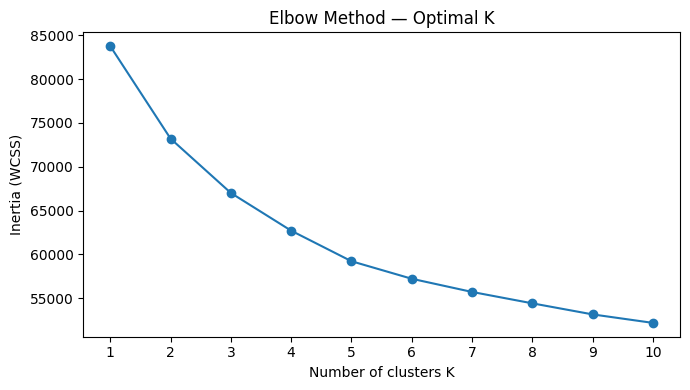

In [4]:
K_range = range(1, 11)
inertias = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_SEED)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K_range), inertias, marker='o')
plt.xlabel('Number of clusters K')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method — Optimal K')
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

## 5. Fit K-Means

In [5]:
K = 3   # adjust based on elbow plot above

kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_SEED)
labels = kmeans.fit_predict(X)

df['cluster'] = labels
print('Cluster sizes:')
print(df['cluster'].value_counts().sort_index())

Cluster sizes:
cluster
0    1098
1     451
2     545
Name: count, dtype: int64


## 6. Interpret the Clusters

Compare cluster-level means for each feature (in original unscaled units) to understand what distinguishes the groups.

In [6]:
cluster_profiles = df.groupby('cluster')[feature_cols + ['AimoScore']].mean()
cluster_profiles

,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,No_10_Angle_Deviation,...,No_19_NASM_Deviation,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,AimoScore
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.511765,0.493719,0.562554,0.470117,0.436067,0.395879,0.464516,0.598022,0.448635,0.388660,...,0.705685,0.683204,0.676515,0.610863,0.689925,0.630592,0.482849,0.443145,0.439128,0.703040
1,0.381692,0.279160,0.503151,0.385506,0.729030,0.530827,0.721424,0.570833,0.598556,0.830099,...,0.694928,0.783348,0.717526,0.712651,0.728595,0.749888,0.675472,0.562617,0.570624,0.417957
2,0.724999,0.712549,0.602893,0.724358,0.492805,0.723973,0.462923,0.766146,0.570136,0.537688,...,0.790740,0.726124,0.757092,0.688410,0.738031,0.673744,0.574114,0.608917,0.611733,0.438313


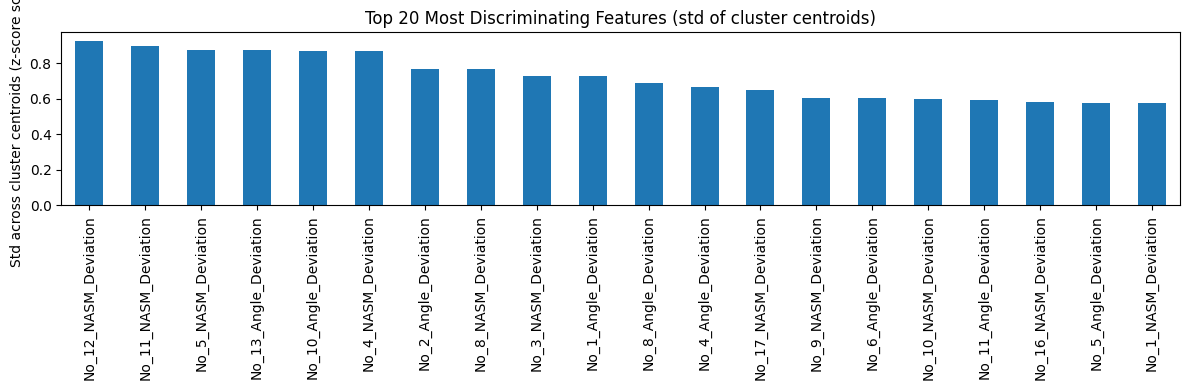


Top 10 most discriminating features:
No_12_NASM_Deviation     0.926304
No_11_NASM_Deviation     0.898593
No_5_NASM_Deviation      0.871350
No_13_Angle_Deviation    0.871350
No_10_Angle_Deviation    0.868265
No_4_NASM_Deviation      0.868265
No_2_Angle_Deviation     0.768246
No_8_NASM_Deviation      0.767994
No_3_NASM_Deviation      0.724516
No_1_Angle_Deviation     0.724516
dtype: float64


In [7]:
# Which features differ most across clusters?
scaled_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=feature_cols,
    index=[f'Cluster {i}' for i in range(K)]
)

centroid_spread = scaled_centers.std(axis=0).sort_values(ascending=False)

plt.figure(figsize=(12, 4))
centroid_spread.head(20).plot(kind='bar')
plt.title('Top 20 Most Discriminating Features (std of cluster centroids)')
plt.ylabel('Std across cluster centroids (z-score scale)')
plt.tight_layout()
plt.show()

print('\nTop 10 most discriminating features:')
print(centroid_spread.head(10))

### Cluster Interpretation

See `A7_cluster_kmeans.ipynb`.

## 7. PCA of the AIMO Observations

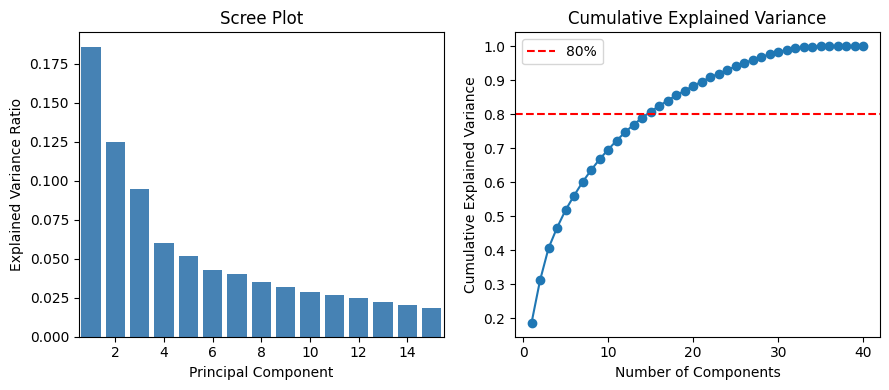

PC1 explains 18.6% of variance
PC2 explains 12.5% of variance
PC1+PC2 together: 31.1%
Components needed to explain 80% of variance: 15


In [8]:
pca = PCA(random_state=RANDOM_SEED)
pca.fit(X)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1)
plt.bar(range(1, len(explained) + 1), explained, color='steelblue')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.xlim(0.5, 15.5)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative) + 1), cumulative, marker='o')
plt.axhline(0.80, color='red', linestyle='--', label='80%')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()

print(f'PC1 explains {explained[0]*100:.1f}% of variance')
print(f'PC2 explains {explained[1]*100:.1f}% of variance')
print(f'PC1+PC2 together: {(explained[0]+explained[1])*100:.1f}%')

n_for_80 = int(np.searchsorted(cumulative, 0.80)) + 1
print(f'Components needed to explain 80% of variance: {n_for_80}')

## 8. 2D Scatterplot — First Two PC Scores Coloured by Cluster

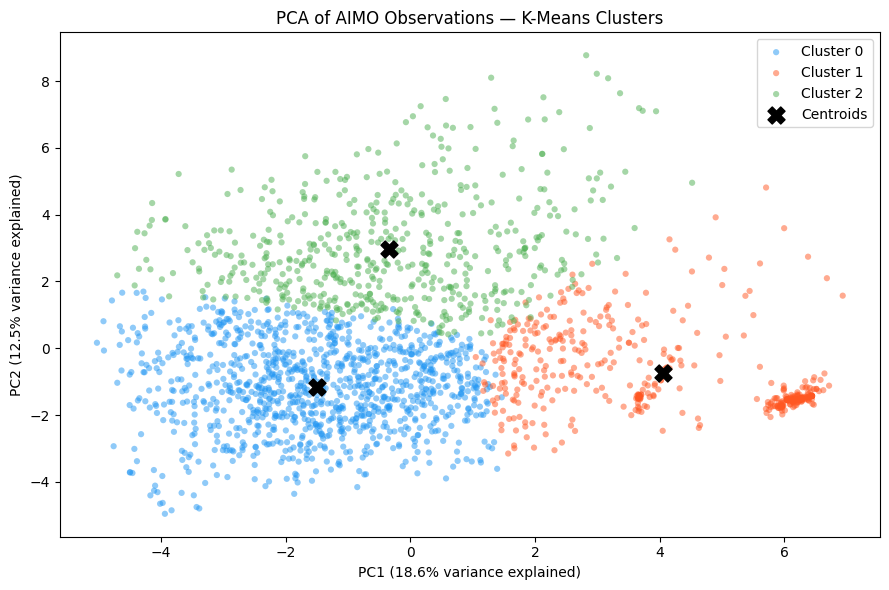

In [9]:
X_pca = pca.transform(X)

colours = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0', '#FF9800']

fig, ax = plt.subplots(figsize=(9, 6))

for c in range(K):
    mask = labels == c
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=colours[c], label=f'Cluster {c}',
        alpha=0.5, s=20, edgecolors='none'
    )

# Project K-means centroids into PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='black', marker='X', s=150, zorder=5, label='Centroids'
)

ax.set_xlabel(f'PC1 ({explained[0]*100:.1f}% variance explained)')
ax.set_ylabel(f'PC2 ({explained[1]*100:.1f}% variance explained)')
ax.set_title('PCA of AIMO Observations — K-Means Clusters')
ax.legend()
plt.tight_layout()
plt.show()